In [1]:
import torch 
import numpy as np 
import matplotlib.pyplot as plt 

from torch import nn

In [2]:
import sys
import os

# Pega o caminho da pasta atual (scripts) e volta um nível para chegar na raiz do projeto
raiz_projeto = os.path.abspath(os.path.join(os.getcwd(), '..'))

# Adiciona a raiz do projeto ao sys.path, se ainda não estiver lá
if raiz_projeto not in sys.path:
    
    sys.path.append(raiz_projeto)

print("Caminho adicionado:", raiz_projeto)

Caminho adicionado: c:\Users\rique\OneDrive\Documentos 1\Doutorado\Disciplina Deep Learning\modelo_adimensionalizado


In [3]:
from src.neural_network import NeuralNetwork
from src.physics_informed_model import IPINN

In [4]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'Usando dispositivo: {device}')

Usando dispositivo: cuda


In [5]:
# Carregando os dados simulados por diferenças finitas
dados = np.load('../dados/data_002.npz')

input = dados['input']
target = dados['target']
param = dados['parameters']

data_total_size = input.shape[0]
print(f'Total de dados: {data_total_size}')

# Filtrando uma amostra aleatória de 1.000 dados experimentais para treinamento
idx = np.random.choice(range(data_total_size), size = 200_000, replace = False)

# Convertendo os dados para tensores do PyTorch
data_input_obs = torch.from_numpy(input[idx]).float().to(device)
data_target_obs = torch.from_numpy(target[idx]).float().to(device)
print(data_input_obs.shape, data_target_obs.shape)

# Definindo dados para condição inicial conhecida
data_input_ic = torch.from_numpy(input[:2500]).float().to(device)
data_target_ic = torch.from_numpy(target[:2500]).float().to(device)

# Definindo os pontos de colocation para o cálculo do resíduo da equação diferencial residual
collocation_points_size = 10_000
x = torch.FloatTensor(collocation_points_size).uniform_(0, 1)
y = torch.FloatTensor(collocation_points_size).uniform_(0, 1)
t = torch.FloatTensor(collocation_points_size).uniform_(0, 1)

collocation_data = torch.vstack([t, x, y]).T.requires_grad_(True).to(device)

trainning_data = {
    'experimental_input': data_input_obs,
    'experimental_target': data_target_obs,
    'ic_input': data_input_ic,
    'ic_target': data_target_ic,
    'collocation_data': collocation_data
}

Total de dados: 200000
torch.Size([200000, 3]) torch.Size([200000, 1])


In [7]:
import time 
import numpy as np


# Carregando os dados simulados por diferenças finitas
dados = np.load('../dados/numericos/data_002.npz')
input = dados['input']
target = dados['target']
param = dados['parameters']
data_total_size = input.shape[0]

ruido = [1e-3, 5e-3, 1e-2, 5e-2, 1e-1, 5e-1]
collocation_points_size = 1_000

for r in ruido:

    model = NeuralNetwork(
        [3] + 3 * [256] + [1],
        nn.Tanh()
    )

    inverse_pinn = IPINN(
        model
    )

    target_com_ruido = target + np.random.normal(0., r, target.shape)

    # Convertendo os dados para tensores do PyTorch
    data_input_obs = torch.from_numpy(input).float().to(device)
    data_target_obs = torch.from_numpy(target_com_ruido).float().to(device)
    #print(data_input_obs.shape, data_target_obs.shape)

    # Definindo dados para condição inicial conhecida
    data_input_ic = torch.from_numpy(input[:2500]).float().to(device)
    data_target_ic = torch.from_numpy(target_com_ruido[:2500]).float().to(device)

    # Definindo os pontos de colocation para o cálculo do resíduo da equação diferencial residual
    x = torch.FloatTensor(collocation_points_size).uniform_(0, 1)
    y = torch.FloatTensor(collocation_points_size).uniform_(0, 1)
    t = torch.FloatTensor(collocation_points_size).uniform_(0, 1)

    collocation_data = torch.vstack([t, x, y]).T.requires_grad_(True).to(device)

    # Agrupando dados de treinamento
    trainning_data = {
        'experimental_input': data_input_obs,
        'experimental_target': data_target_obs,
        'ic_input': data_input_ic,
        'ic_target': data_target_ic,
        'collocation_data': collocation_data
    }

    inicio = time.perf_counter()
    history = inverse_pinn.fit(
        trainning_data,
        1_000,
        device = device
    )
    fim = time.perf_counter()

    # Verificando proporção dos dados utilizada
    print(f'Proporção dos Ruido: {r}')

    # Verificando tempo de treinamento
    h, resto = divmod(int(fim - inicio), 3600)
    m, s = divmod(resto, 60)
    print(f'Tempo de Treinamento: {h}h {m}m {s}seg')

    # Verificando precisão da inferência de D*
    dl_estimado = torch.exp(inverse_pinn.log_d).item()
    dl_ref = (param[0] / (param[1] * param[2] ** 2)).item()
    erro = np.linalg.norm(dl_estimado - dl_ref) / np.linalg.norm(dl_ref)
    print(f'Erro: {erro:.2%}    Estimado: {dl_estimado:.7f}     Referência: {dl_ref:.7f}')

    print('-' * 50)



100%|██████████| 1000/1000 [00:44<00:00, 22.51it/s]


Proporção dos Ruido: 0.001
Tempo de Treinamento: 0h 0m 44seg
Erro: 6.38%    Estimado: 0.0074209     Referência: 0.0079268
--------------------------------------------------


100%|██████████| 1000/1000 [00:43<00:00, 22.74it/s]


Proporção dos Ruido: 0.005
Tempo de Treinamento: 0h 0m 43seg
Erro: 3.87%    Estimado: 0.0082337     Referência: 0.0079268
--------------------------------------------------


100%|██████████| 1000/1000 [00:42<00:00, 23.28it/s]


Proporção dos Ruido: 0.01
Tempo de Treinamento: 0h 0m 42seg
Erro: 15.33%    Estimado: 0.0091417     Referência: 0.0079268
--------------------------------------------------


... (2 outputs left out)

100%|██████████| 1000/1000 [00:43<00:00, 23.11it/s]


Proporção dos Ruido: 0.1
Tempo de Treinamento: 0h 0m 43seg
Erro: 80.36%    Estimado: 0.0142971     Referência: 0.0079268
--------------------------------------------------


100%|██████████| 1000/1000 [00:43<00:00, 23.14it/s]

Proporção dos Ruido: 0.5
Tempo de Treinamento: 0h 0m 43seg
Erro: 25.31%    Estimado: 0.0059203     Referência: 0.0079268
--------------------------------------------------


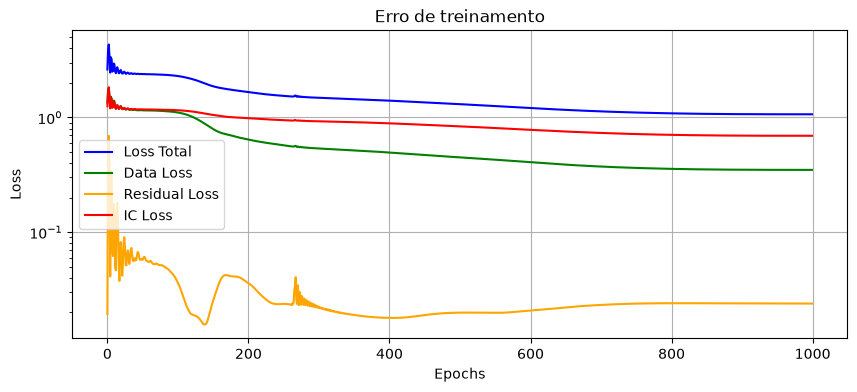

In [8]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))
plt.plot(history['loss'], label='Loss Total', color='blue')
plt.plot(history['data_loss'], label='Data Loss', color='green')
plt.plot(history['residual_loss'], label='Residual Loss', color='orange')
plt.plot(history['ic_loss'], label='IC Loss', color='red')
plt.yscale('log')
plt.title('Erro de treinamento')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.grid()
plt.legend()
plt.show()

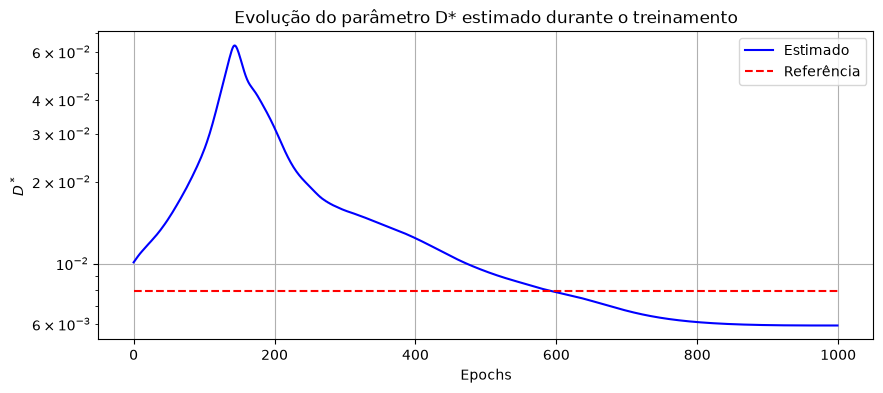

In [9]:
plt.figure(figsize=(10, 4))
plt.plot(history['dl'], label = r'Estimado', color='blue')
plt.hlines(dl_ref, 0, len(history['dl']), colors='red', linestyles='dashed', label= r'Referência')
plt.yscale('log')
plt.title('Evolução do parâmetro D* estimado durante o treinamento')
plt.xlabel('Epochs')
plt.ylabel(r'$D^*$')
plt.grid()
plt.legend()
plt.show()

In [10]:
input_tensor = torch.from_numpy(input).float().to(device)
with torch.no_grad(): pred = model(input_tensor).cpu().detach().numpy().reshape(80, 50, 50)

target = target.reshape(80, 50, 50)

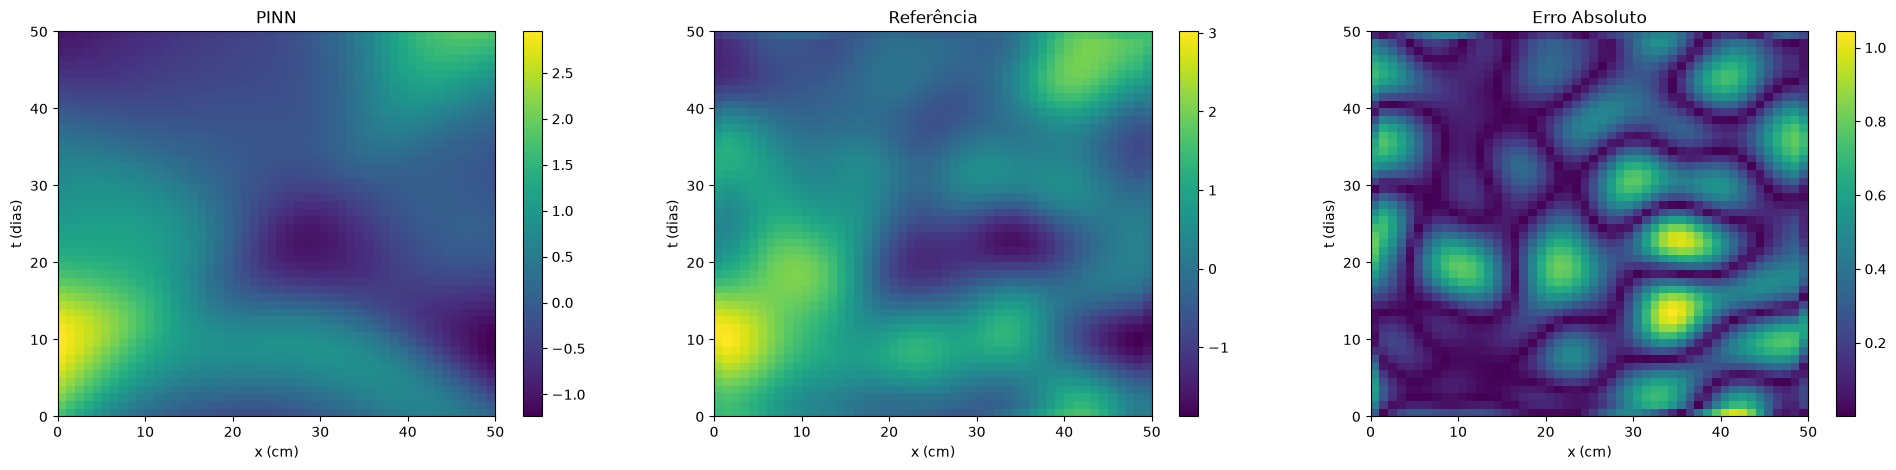

In [11]:
index = 20
fig, ax = plt.subplots(ncols = 3, figsize = (24, 5))

p0 = ax[0].pcolormesh(pred[index])
p1 = ax[1].pcolormesh(target[index])
p2 = ax[2].pcolormesh(np.abs(target[index] - pred[index]))

ax[0].set_xlabel('x (cm)')
ax[0].set_ylabel('t (dias)')
ax[0].set_title('PINN')

ax[1].set_xlabel('x (cm)')
ax[1].set_ylabel('t (dias)')
ax[1].set_title('Referência')

ax[2].set_xlabel('x (cm)')
ax[2].set_ylabel('t (dias)')
ax[2].set_title('Erro Absoluto')

plt.colorbar(p0)
plt.colorbar(p1)
plt.colorbar(p2)
plt.show()